In [2]:
import obspy
from obspy import read
from geopy.distance import geodesic
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import datetime
from obspy.signal.filter import lowpass
from obspy.clients.fdsn.client import Client
import json
import scipy
import xarray as xr
from matplotlib.colors import LightSource
import cartopy.crs as ccrs         # to plot maps with different projections
import cartopy.feature as cfeature # to plot coastlines, land, borders, etc.
import json
import matplotlib
from matplotlib import colors
from pyproj import Proj
from geopy.distance import geodesic
import pickle
import matplotlib.animation as animation
matplotlib.rcParams['font.family'] = ['Arial']
plt.rcParams.update({'font.size': 14}) 
from math import radians, cos, sin, atan2, sqrt, degrees
import imageio
from itertools import product
import dask
from dask.diagnostics import ProgressBar
with open('/Users/zoekrauss/offshore_eew_modeling/location/PB2002_boundaries.json', 'r') as f:
    plate_boundaries = json.load(f)

In [2]:
# I have 7101 miniseeds

In [3]:
# Read station/channel metadata into Python lists
file_path = '20241205_cape_mendocino.seismic.dat'

network, station, location, channel = [], [], [], []
latitude, longitude, elevation = [], [], []
samplerate, gain, units = [], [], []
azimuth, dip, sensortype = [], [], []

with open(file_path) as f:
    for line in f:
        if not line.strip() or line.startswith("#"):
            continue

        p = line.split(maxsplit=13)
        network.append(p[0])
        station.append(p[1])
        location.append(p[2])
        channel.append(p[3])
        latitude.append(float(p[4]))
        longitude.append(float(p[5]))
        elevation.append(float(p[6]))
        samplerate.append(float(p[7]))
        gain.append(float(p[8]))
        units.append(p[9])
        azimuth.append(float(p[11]))
        dip.append(float(p[12]))
        sensortype.append(p[13].strip())

# Example: find all rows for one station/channel
wanted_station = "BZN"
wanted_channel = "HHZ"

matches = [i for i, (s, c) in enumerate(zip(station, channel))
           if s == wanted_station and c == wanted_channel]

for i in matches:
    print(latitude[i], longitude[i], elevation[i], sensortype[i])

33.4915 -116.667 1301.0 Streckeisen STS-2 G1/Quanterra 330 Linear Phase Be


In [4]:
hypo_lat = 40.374
hypo_lon = -125.022

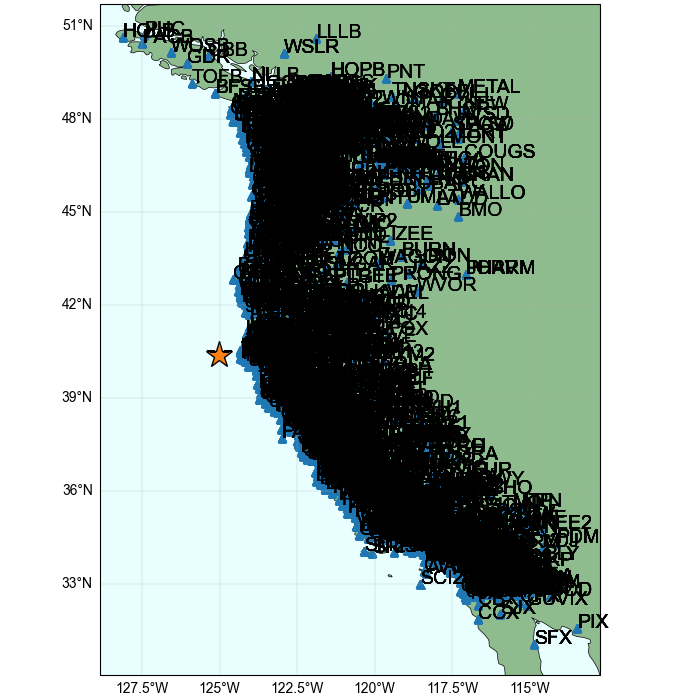

In [5]:
%matplotlib widget

fig = plt.figure(figsize=[7,7],constrained_layout=True)
ax=fig.add_subplot(projection=ccrs.PlateCarree(central_longitude=0))
ax.coastlines(linewidth=0.5)
# ax.add_feature(cfeature.LAND, facecolor='honeydew') 
ax.add_feature(cfeature.LAND, facecolor='darkseagreen') 
ax.add_feature(cfeature.OCEAN, facecolor='lightcyan',alpha=0.7)

ax.plot(longitude,latitude,'^')
ax.plot(hypo_lon,hypo_lat,'*',markersize=20,markeredgecolor='k')
for i in range(len(longitude)):
    ax.text(longitude[i],latitude[i],station[i])

gl = ax.gridlines(draw_labels=True,linewidth=0.2) 
gl.xlabel_style = {'size':10}
gl.ylabel_style = {'size':10}
gl.top_labels = False
gl.right_labels = False
# gl.bottom_labels=False

In [6]:
# 1725, KCT, WLKR, 89101, PETL, KCO, KSM, KPR, RVOW, KMPB, PRDS, 1023, 1584B, 89101, 1586

In [7]:
import glob
mseed = glob.glob('/Users/zoekrauss/shakealert_8hz/downsampled_mseeds/mendocino_miniseed_files00/*WLKR*')
print(len(mseed))

6


WLKR
WLKR
WLKR
WLKR
WLKR
WLKR


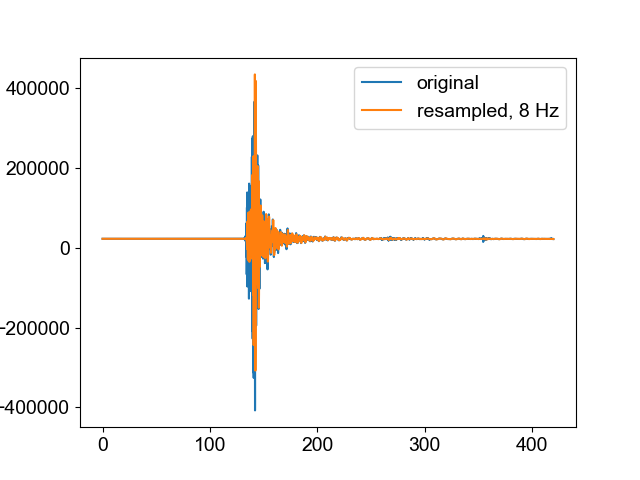

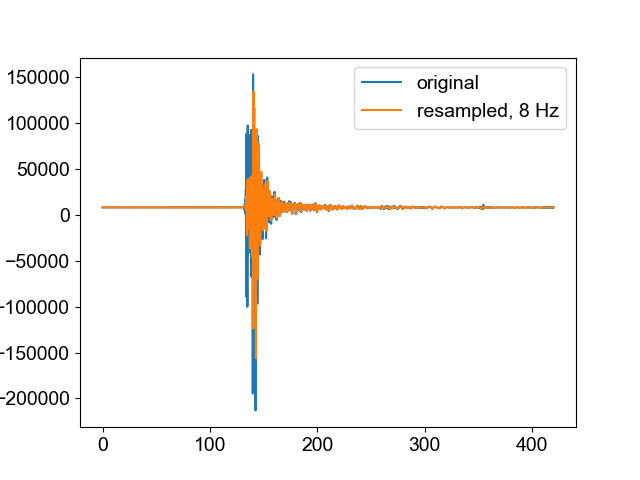

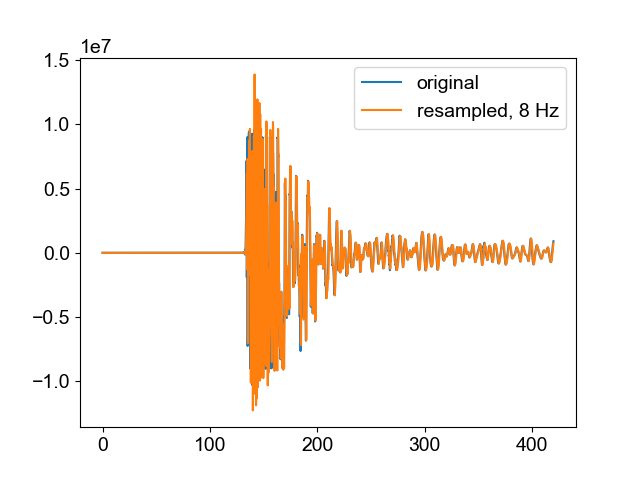

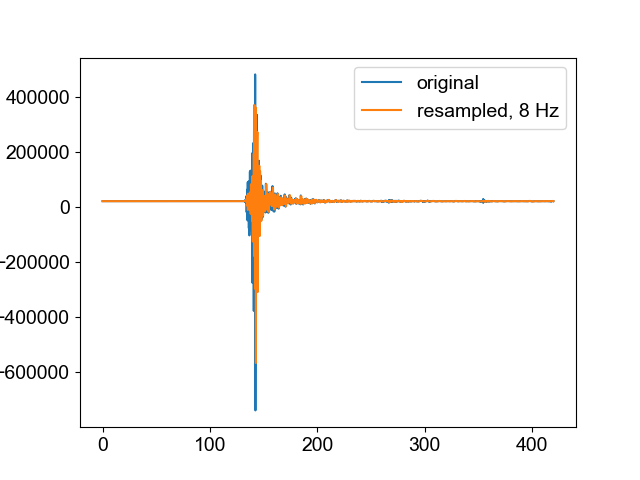

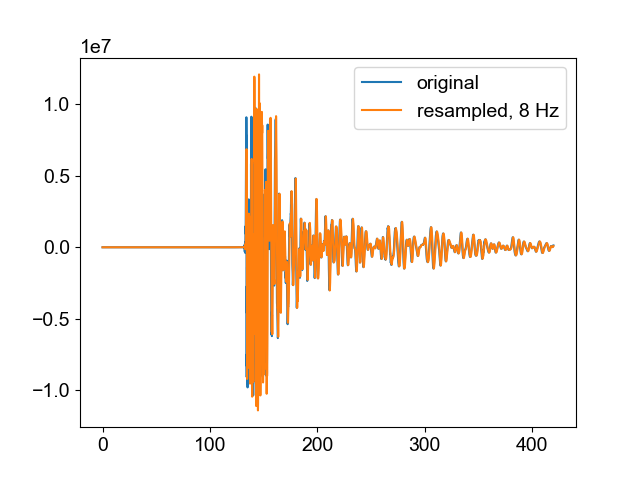

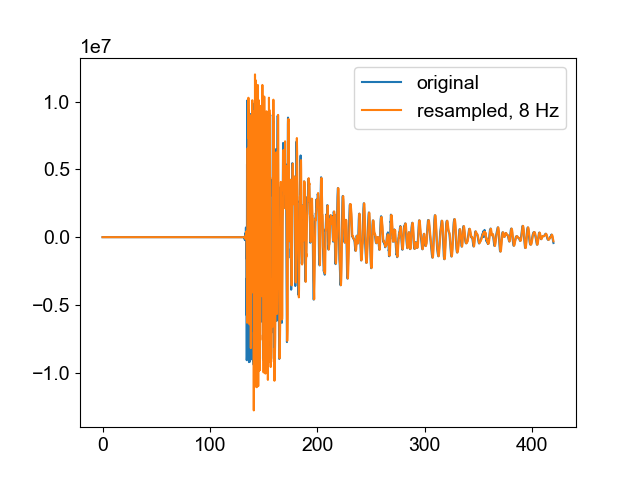

In [8]:
%matplotlib widget

for i in range(len(mseed)):
    fig,ax = plt.subplots(1)
    st = read(mseed[i])
    # st2 = st.copy()
    # t1 = st2[0].stats.starttime
    # t2 = st2[0].stats.endtime
    # st2.trim(t1-5,t2+5,fill_value=np.int32(np.mean(st2[0].data)),pad=True)


    print(st[0].stats.station)
    # Now downsample
    st2 = st.copy()
    t1 = st2[0].stats.starttime
    t2 = st2[0].stats.endtime
    st2.trim(t1-100,t2,fill_value=np.int32(np.mean(st2[0].data[0:10])),pad=True) # pad ends so we can cut off edge effects
    st2.trim(t1-100,t2+100,fill_value=np.int32(np.mean(st2[0].data[-10:])),pad=True)

    # If sampling rate is too large, need to do smaller steps:
    if st2[0].stats.sampling_rate/8 > 16:
        st2.resample(40.0, no_filter=False) # do a smaller resampling step first
    st2.resample(8.0,no_filter=False)
    st2.trim(t1,t2) # cut off edge effects
    
    # st2.resample(8.0,no_filter=False)
    # st2.trim(t1,t2)
    
    
    # ax.plot(st[i].times(),st[i].data)
    ax.plot(st[0].times(),st[0].data,label='original')
    ax.plot(st2[0].times(),st2[0].data,label='resampled, 8 Hz')
    ax.legend()

## Read the miniseeds and downsample

In [12]:
import glob
all_miniseeds =  glob.glob('/Users/zoekrauss/shakealert_8hz/downsampled_mseeds/mendocino_miniseed_files00/*')

In [ ]:
all_miniseeds

In [13]:
networks = []
stations = []
channels = []
lats = []
lons = []
max_raw_amp = []
median_raw_amp = []
max_ds_amp = []
median_ds_amp = []
write_path = 'mendocino_first10_downsampled_mseeds'

In [14]:
# first10 = ['1725', 'KCT', 'WLKR', '89101', 'PETL', 'KCO', 'KSM', 'KPR', 'RVOW', 'KMPB', 'PRDS', '1023', '1584B', '89101', '1586']
first_stations=['PETL','WLKR','KCT','KCO','1584B','89101','1023','KSM','1586','1582'] # this from EPIC files

In [16]:
for i in range(len(all_miniseeds)):
# for i in range(10):
    mseed = all_miniseeds[i]
    st = read(mseed)

    networks.append(st[0].stats.network)
    stations.append(st[0].stats.station)
    channels.append(st[0].stats.channel)

    # If station not in dat list, skip it
    if st[0].stats.station not in station:
        continue

    dat_ind = [j for j,s in enumerate(station) if s==st[0].stats.station][0]
    lats.append(latitude[dat_ind])
    lons.append(longitude[dat_ind])

    # Get original amplitudes
    max_raw_amp.append(np.max(np.abs(st[0].data)))
    median_raw_amp.append(np.mean(st[0].data))

    # Below if only downsampling some
    if st[0].stats.station in first_stations:
        print(st[0].stats.station)
        # Now downsample
        st2 = st.copy()
        t1 = st2[0].stats.starttime
        t2 = st2[0].stats.endtime
        st2.trim(t1-100,t2,fill_value=np.int32(np.mean(st2[0].data[0:10])),pad=True) # pad ends so we can cut off edge effects
        st2.trim(t1-100,t2+100,fill_value=np.int32(np.mean(st2[0].data[-10:])),pad=True)

        # If sampling rate is too large, need to do smaller steps:
        if st2[0].stats.sampling_rate/8 > 16:
            st2.resample(40.0, no_filter=False) # do a smaller resampling step first
        st2.resample(8.0,no_filter=False)
        st2.trim(t1,t2) # cut off edge effects
    else:
        st2 = st.copy()
    
    # Below if downsampling all
    # st2 = st.copy()
    # t1 = st2[0].stats.starttime
    # t2 = st2[0].stats.endtime
    # st2.trim(t1-100,t2,fill_value=np.int32(np.mean(st2[0].data[0:10])),pad=True) # pad ends so we can cut off edge effects
    # st2.trim(t1-100,t2+100,fill_value=np.int32(np.mean(st2[0].data[-10:])),pad=True)
        
    # # If sampling rate is too large, need to do smaller steps:
    # if st2[0].stats.sampling_rate/8 > 16:
    #     st2.resample(40.0, no_filter=False) # do a smaller resampling step first
    # st2.resample(8.0,no_filter=False)
    # st2.trim(t1,t2) # cut off edge effects

    # Get downsampled amplitudes
    max_ds_amp.append(np.max(np.abs(st2[0].data)))
    median_ds_amp.append(np.mean(st2[0].data))

    # Convert to int 
    tr = st2[0]
    tr.data = tr.data.astype(int)

    # Write to file
    # mseed_name = '.'.join(['first10_downsampled_mendocino']+mseed.split('.')[1:])
    mseed_name = mseed.split('/')[-1]
    tr.write(write_path + '/' + mseed_name, format = 'MSEED')

/Users/zoekrauss/miniconda3/envs/seiscloud/lib/python3.8/site-packages/obspy/io/mseed/core.py:1034: UserWarning: The encoding specified in trace.stats.mseed.encoding does not match the dtype of the data.
A suitable encoding will be chosen.
  warnings.warn(msg, UserWarning)


WLKR
WLKR
WLKR
WLKR
WLKR
WLKR
KCT
1582
1586
KCT
PETL
89101
KCO
1023
1584B
PETL
PETL
1586
KCO
1584B
1023
KCT
KCT
KSM
1582
1586
89101
KCT
KSM
1584B
KCO
PETL
89101
PETL
1582
PETL
KCT
1023
KSM


## Write .dat file

In [64]:
# Read station/channel metadata into Python lists
file_path = '20241205_cape_mendocino.seismic.dat'

network, station, location, channel = [], [], [], []
latitude, longitude, elevation = [], [], []
samplerate, gain, units = [], [], []
groundmotionclip, azimuth, dip, sensortype = [], [], [], []

with open(file_path) as f:
    for line in f:
        if not line.strip() or line.startswith("#"):
            continue

        p = line.split(maxsplit=13)
        
        # To exclude first stations:
        if p[1] in first_stations:
            continue
            
        network.append(p[0])
        station.append(p[1])
        location.append(p[2])
        channel.append(p[3])
        latitude.append(float(p[4]))
        longitude.append(float(p[5]))
        elevation.append(float(p[6]))

        # Manual sampling rate
        if p[1] in first_stations:
            samplerate.append('8.0')
        else:
            samplerate.append(float(p[7]))
        
        gain.append(p[8])
        units.append(p[9])
        groundmotionclip.append(p[10])
        azimuth.append(p[11])
        dip.append(p[12])
        sensortype.append(p[13].strip())

In [65]:
new_dat = pd.DataFrame({'network':network,'station':station,'location':location,'channel':channel,'latitude':latitude,
                       'longitude':longitude,'elevation':elevation,'samplerate':samplerate,'gain':gain,'units':units,'groundmotionclip':groundmotionclip,
                       'azimuth':azimuth,'dip':dip,'sensortype':sensortype})
len(new_dat)
# new_dat[new_dat['station']=='PETL']

7595

In [66]:
new_dat

,network,station,location,channel,latitude,longitude,elevation,samplerate,gain,units,groundmotionclip,azimuth,dip,sensortype
0,AZ,BZN,--,HHE,33.4915,-116.6670,1301.0,100.0,6.299190e+06,counts/(cm/sec),1.331696,90.0,0.0,Streckeisen STS-2 G1/Quanterra 330 Linear Phas...
1,AZ,BZN,--,HHN,33.4915,-116.6670,1301.0,100.0,6.299190e+06,counts/(cm/sec),1.331696,0.0,0.0,Streckeisen STS-2 G1/Quanterra 330 Linear Phas...
2,AZ,BZN,--,HHZ,33.4915,-116.6670,1301.0,100.0,6.299190e+06,counts/(cm/sec),1.331696,0.0,-90.0,Streckeisen STS-2 G1/Quanterra 330 Linear Phas...
3,AZ,BZN,--,HNE,33.4915,-116.6670,1301.0,100.0,4.278940e+03,counts/(cm/sec2),1960.440670,90.0,0.0,Episensor 200 Hz 10 Volt per g/Quanterra 330 L...
4,AZ,BZN,--,HNN,33.4915,-116.6670,1301.0,100.0,4.278940e+03,counts/(cm/sec2),1960.440670,0.0,0.0,Episensor 200 Hz 10 Volt per g/Quanterra 330 L...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7590,UW,YPT,--,ENN,46.0486,-118.9633,339.0,100.0,2.040000e+05,DU/M/S**2,0.026000,0.0,0.0,"CASCADIA COMPACT,Accelerometer,NANOMETRICS"
7591,UW,YPT,--,ENZ,46.0486,-118.9633,339.0,100.0,2.040000e+05,DU/M/S**2,0.026000,0.0,-90.0,"CASCADIA COMPACT,Accelerometer,NANOMETRICS"
7592,UW,YPT,--,HHE,46.0486,-118.9633,339.0,100.0,3.017200e+08,DU/M/S,0.026000,90.0,0.0,"CASCADIA COMPACT,Velocity Sensor,NANOMETRICS"
7593,UW,YPT,--,HHN,46.0486,-118.9633,339.0,100.0,3.017200e+08,DU/M/S,0.026000,0.0,0.0,"CASCADIA COMPACT,Velocity Sensor,NANOMETRICS"


In [48]:
new_dat.to_csv('first10_excluded_mendocino_mseeds.dat', sep = '\t', index = False, header = False)

In [83]:
!tar czf first10_downsampled_mendocino_mseeds.tar.gz mendocino_first10_downsampled_mseeds
# scp /Users/zoekrauss/shakealert_8hz/downsampled_mseeds/first10_downsampled_mendocino_mseeds.tar.gz zkrauss@eew-uw-dev1.ess.washington.edu:/data/eewdata/miniseeds/downsampled_mendocino


## Look at mseeds

In [21]:
st = obspy.read('/Users/zoekrauss/shakealert_8hz/downsampled_mseeds/mendocino_first10_downsampled_mseeds/PETL.BK.HNZ.00.D.2024.340.184221')

In [22]:
# HH gain
gain = 2.141760e+05

(100.0, 200.0)

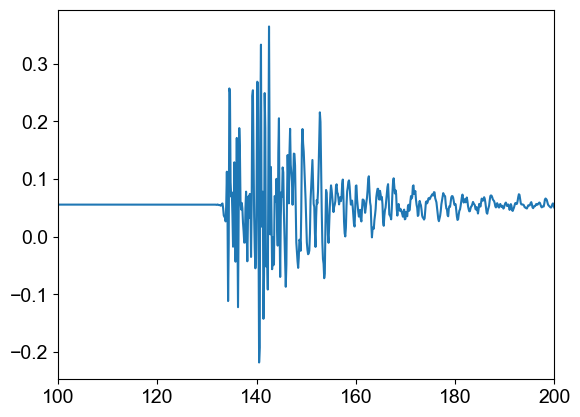

In [23]:
fig,ax = plt.subplots(1)
ax.plot(st[0].times(),st[0].data/gain)
ax.set_xlim(100,200)

In [24]:
st = obspy.read('/Users/zoekrauss/shakealert_8hz/downsampled_mseeds/mendocino_miniseed_files00/PETL.BK.HNZ.00.D.2024.340.184221')

(100.0, 200.0)

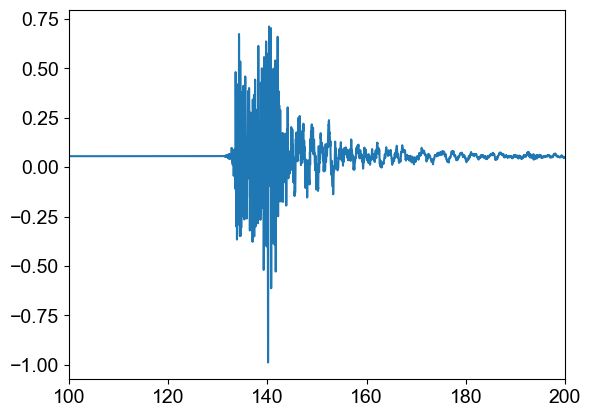

In [25]:
fig,ax = plt.subplots(1)
ax.plot(st[0].times(),st[0].data/gain)
ax.set_xlim(100,200)